# Redes de interação de Game of Thrones (T1 x T8)

Compara as redes de interação entre personagens da 1ª e da 8ª temporada em três etapas:
1. métricas estruturais e histogramas de grau;
2. centralidades;
3. detecção de comunidades e visualização dos grafos.

Dados: [mathbeveridge/gameofthrones](https://github.com/mathbeveridge/gameofthrones), de Andrew Beveridge ([CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/)). O notebook baixa os arquivos direto da fonte.

In [1]:
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

from networkx.algorithms.community import greedy_modularity_communities

# Arestas de cada temporada (Source, Target, Weight), baixadas da fonte original
URL = "https://raw.githubusercontent.com/mathbeveridge/gameofthrones/master/data/got-s{}-edges.csv"
S1 = pd.read_csv(URL.format(1))
S8 = pd.read_csv(URL.format(8))

G1 = nx.from_pandas_edgelist(
    S1, source="Source", target="Target", edge_attr="Weight", create_using=nx.Graph()
)

G8 = nx.from_pandas_edgelist(
    S8, source="Source", target="Target", edge_attr="Weight", create_using=nx.Graph()
)

print("T1:", G1.number_of_nodes(), "vértices e", G1.number_of_edges(), "arestas")
print("T8:", G8.number_of_nodes(), "vértices e", G8.number_of_edges(), "arestas")


T1: 126 vértices e 549 arestas
T8: 74 vértices e 553 arestas


## Tarefa 1: Métricas estruturais e histogramas

In [2]:
def metricas_basicas(G):
    graus = np.array([d for _, d in G.degree()])
    return {
        "Vértices": G.number_of_nodes(),
        "Arestas": G.number_of_edges(),
        "Grau médio": graus.mean(),
        "Grau mediano": np.median(graus),
        "Grau mínimo": graus.min(),
        "Grau máximo": graus.max(),
        "Densidade": nx.density(G),
        "Transitividade": nx.transitivity(G),
        "Conectado?": nx.is_connected(G),
        "Componentes": nx.number_connected_components(G),
    }

metricas = pd.DataFrame({
    "Temporada 1": metricas_basicas(G1),
    "Temporada 8": metricas_basicas(G8),
})

metricas


,Temporada 1,Temporada 8
Vértices,126,74
Arestas,549,553
Grau médio,8.714286,14.945946
Grau mediano,6.0,11.0
Grau mínimo,1,1
Grau máximo,57,42
Densidade,0.069714,0.204739
Transitividade,0.383252,0.644184
Conectado?,True,False
Componentes,1,2


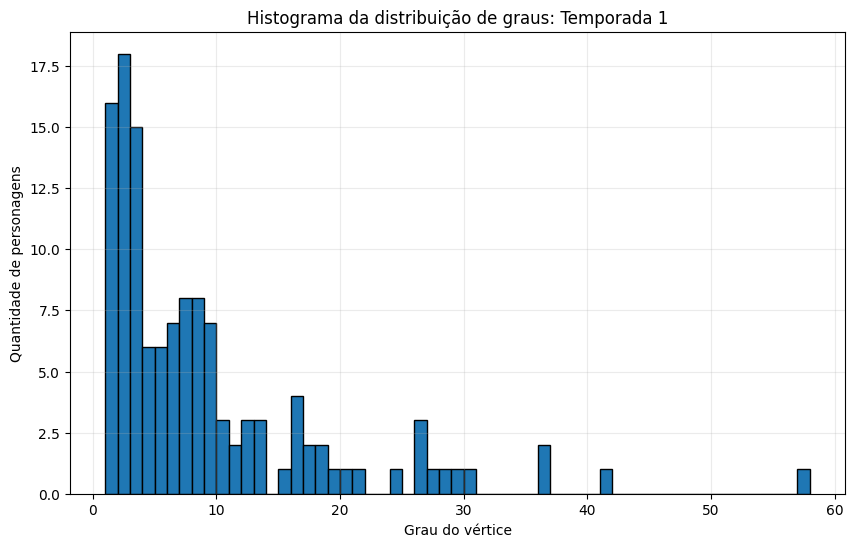

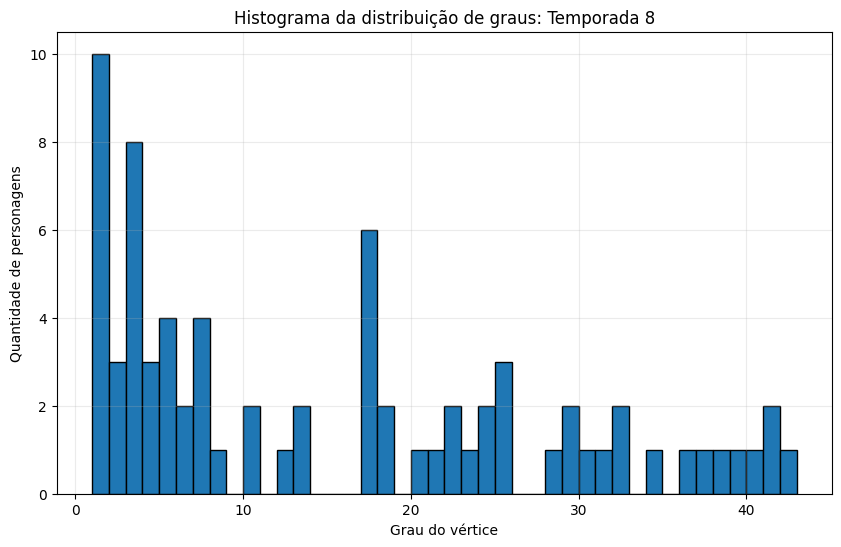

In [3]:
def plot_histograma_graus(G, titulo):
    graus = [d for _, d in G.degree()]
    plt.figure(figsize=(10, 6))
    plt.hist(graus, bins=range(min(graus), max(graus) + 2), edgecolor="black")
    plt.title(titulo)
    plt.xlabel("Grau do vértice")
    plt.ylabel("Quantidade de personagens")
    plt.grid(True, alpha=0.25)
    plt.show()

plot_histograma_graus(G1, "Histograma da distribuição de graus: Temporada 1")
plot_histograma_graus(G8, "Histograma da distribuição de graus: Temporada 8")


## Tarefa 2: Top 3 personagens por centralidade

In [4]:
def top3_centralidades(G):
    medidas = {
        "Grau": nx.degree_centrality(G),
        "Intermediação": nx.betweenness_centrality(G, normalized=True),
        "Proximidade": nx.closeness_centrality(G),
        "Autovetor": nx.eigenvector_centrality(G, max_iter=10000),
    }

    linhas = []
    for medida, valores in medidas.items():
        for pos, (personagem, valor) in enumerate(
            sorted(valores.items(), key=lambda x: x[1], reverse=True)[:3], start=1
        ):
            linhas.append({
                "Medida": medida,
                "Posição": pos,
                "Personagem": personagem,
                "Valor": valor,
            })
    return pd.DataFrame(linhas)

centralidades_t1 = top3_centralidades(G1)
centralidades_t8 = top3_centralidades(G8)

display(centralidades_t1)
display(centralidades_t8)


,Medida,Posição,Personagem,Valor
0,Grau,1,NED,0.456000
1,Grau,2,TYRION,0.328000
2,Grau,3,ROBERT,0.288000
3,Intermediação,1,NED,0.303280
4,Intermediação,2,TYRION,0.163027
5,Intermediação,3,CATELYN,0.118284
6,Proximidade,1,NED,0.628141
7,Proximidade,2,ROBERT,0.553097
8,Proximidade,3,CATELYN,0.550661
9,Autovetor,1,NED,0.315082


,Medida,Posição,Personagem,Valor
0,Grau,1,SAM,0.575342
1,Grau,2,DAENERYS,0.561644
2,Grau,3,TYRION,0.561644
3,Intermediação,1,DAENERYS,0.133902
4,Intermediação,2,SAM,0.099133
5,Intermediação,3,ARYA,0.099021
6,Proximidade,1,SAM,0.677008
7,Proximidade,2,DAENERYS,0.670435
8,Proximidade,3,TYRION,0.670435
9,Autovetor,1,TYRION,0.217896


## Tarefa 3: Comunidades

In [5]:
def detectar_comunidades(G):
    comunidades = list(greedy_modularity_communities(G, weight="Weight"))
    comunidades = sorted(comunidades, key=lambda c: (-len(c), sorted(c)[0]))
    no_para_comunidade = {}
    for i, comunidade in enumerate(comunidades):
        for no in comunidade:
            no_para_comunidade[no] = i
    return comunidades, no_para_comunidade

comunidades_t1, mapa_t1 = detectar_comunidades(G1)
comunidades_t8, mapa_t8 = detectar_comunidades(G8)

print("Temporada 1:", len(comunidades_t1), "comunidades")
print("Tamanhos:", [len(c) for c in comunidades_t1])
print()
print("Temporada 8:", len(comunidades_t8), "comunidades")
print("Tamanhos:", [len(c) for c in comunidades_t8])


Temporada 1: 7 comunidades
Tamanhos: [44, 23, 19, 17, 17, 4, 2]

Temporada 8: 6 comunidades
Tamanhos: [20, 17, 12, 12, 11, 2]


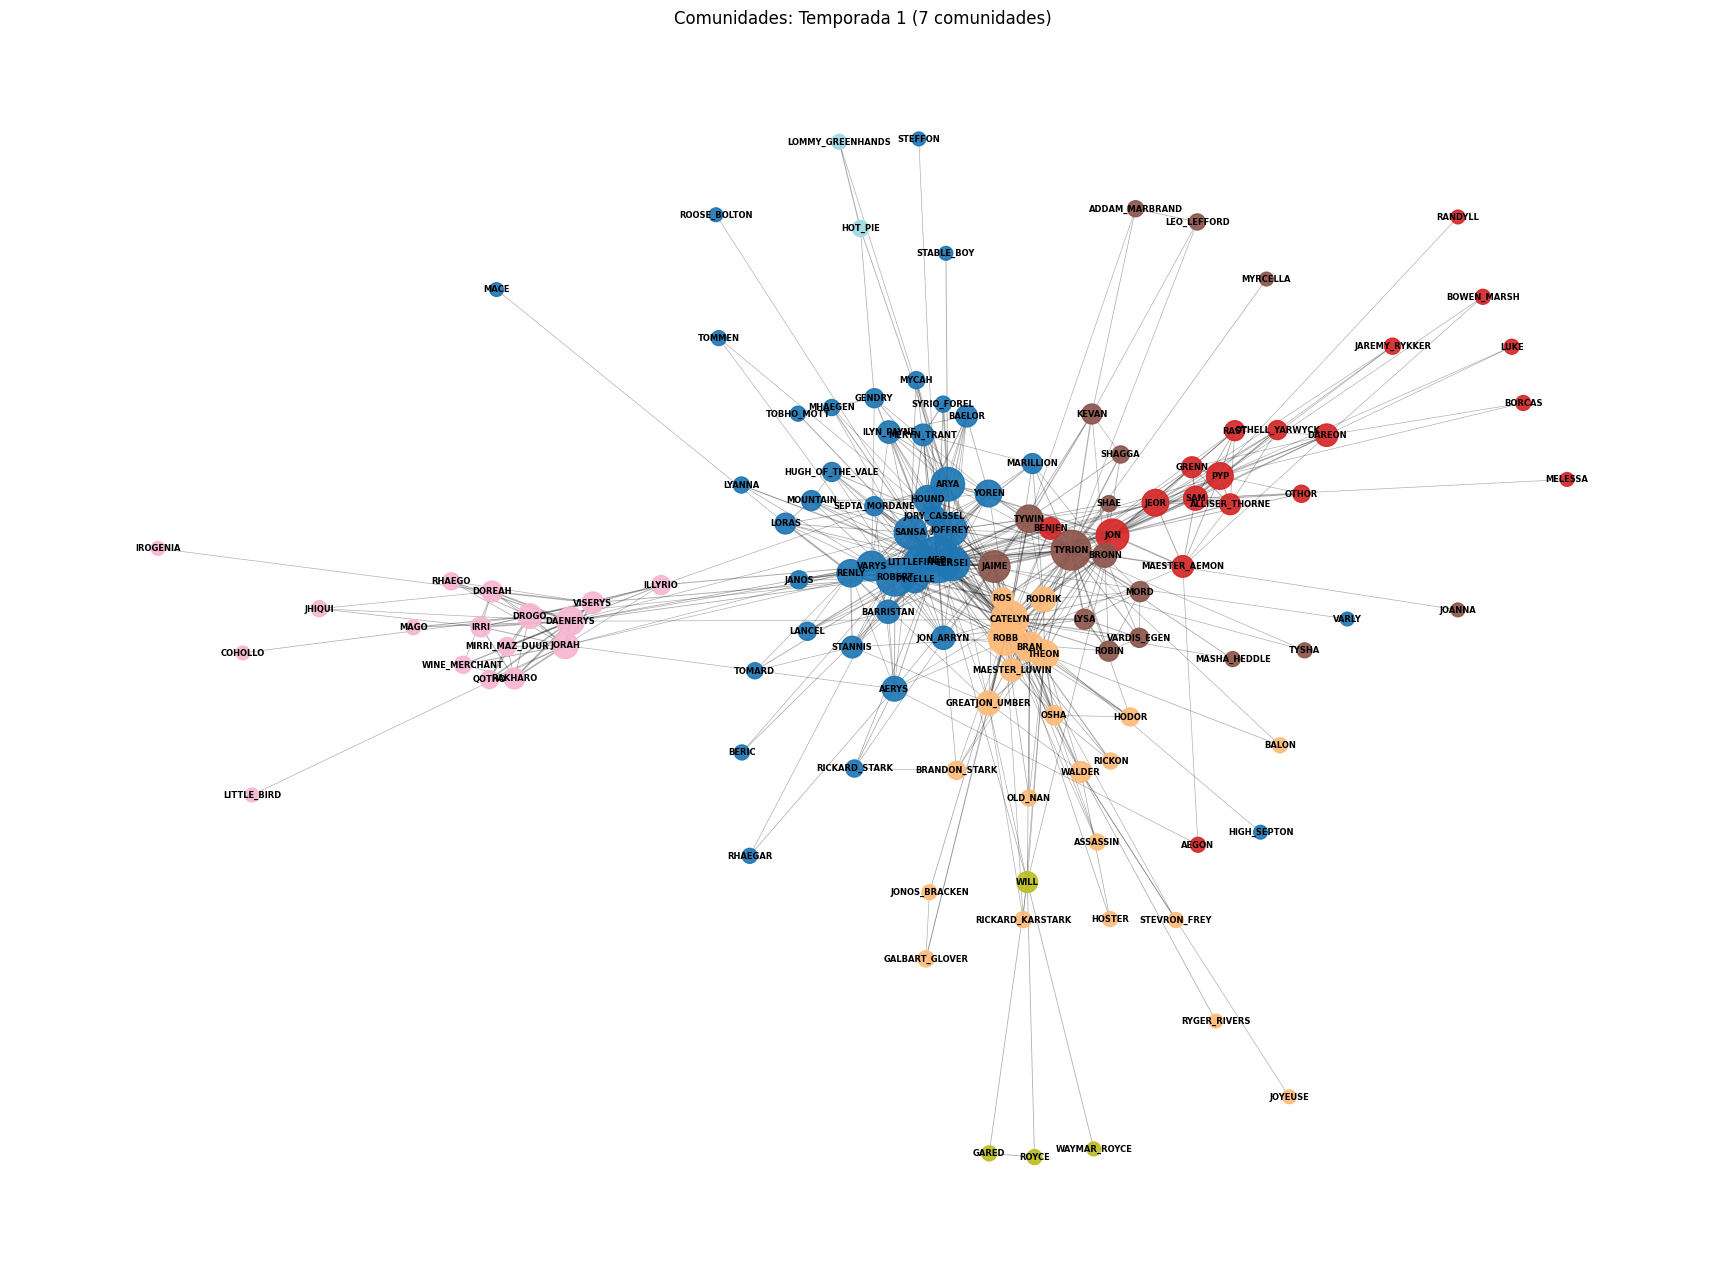

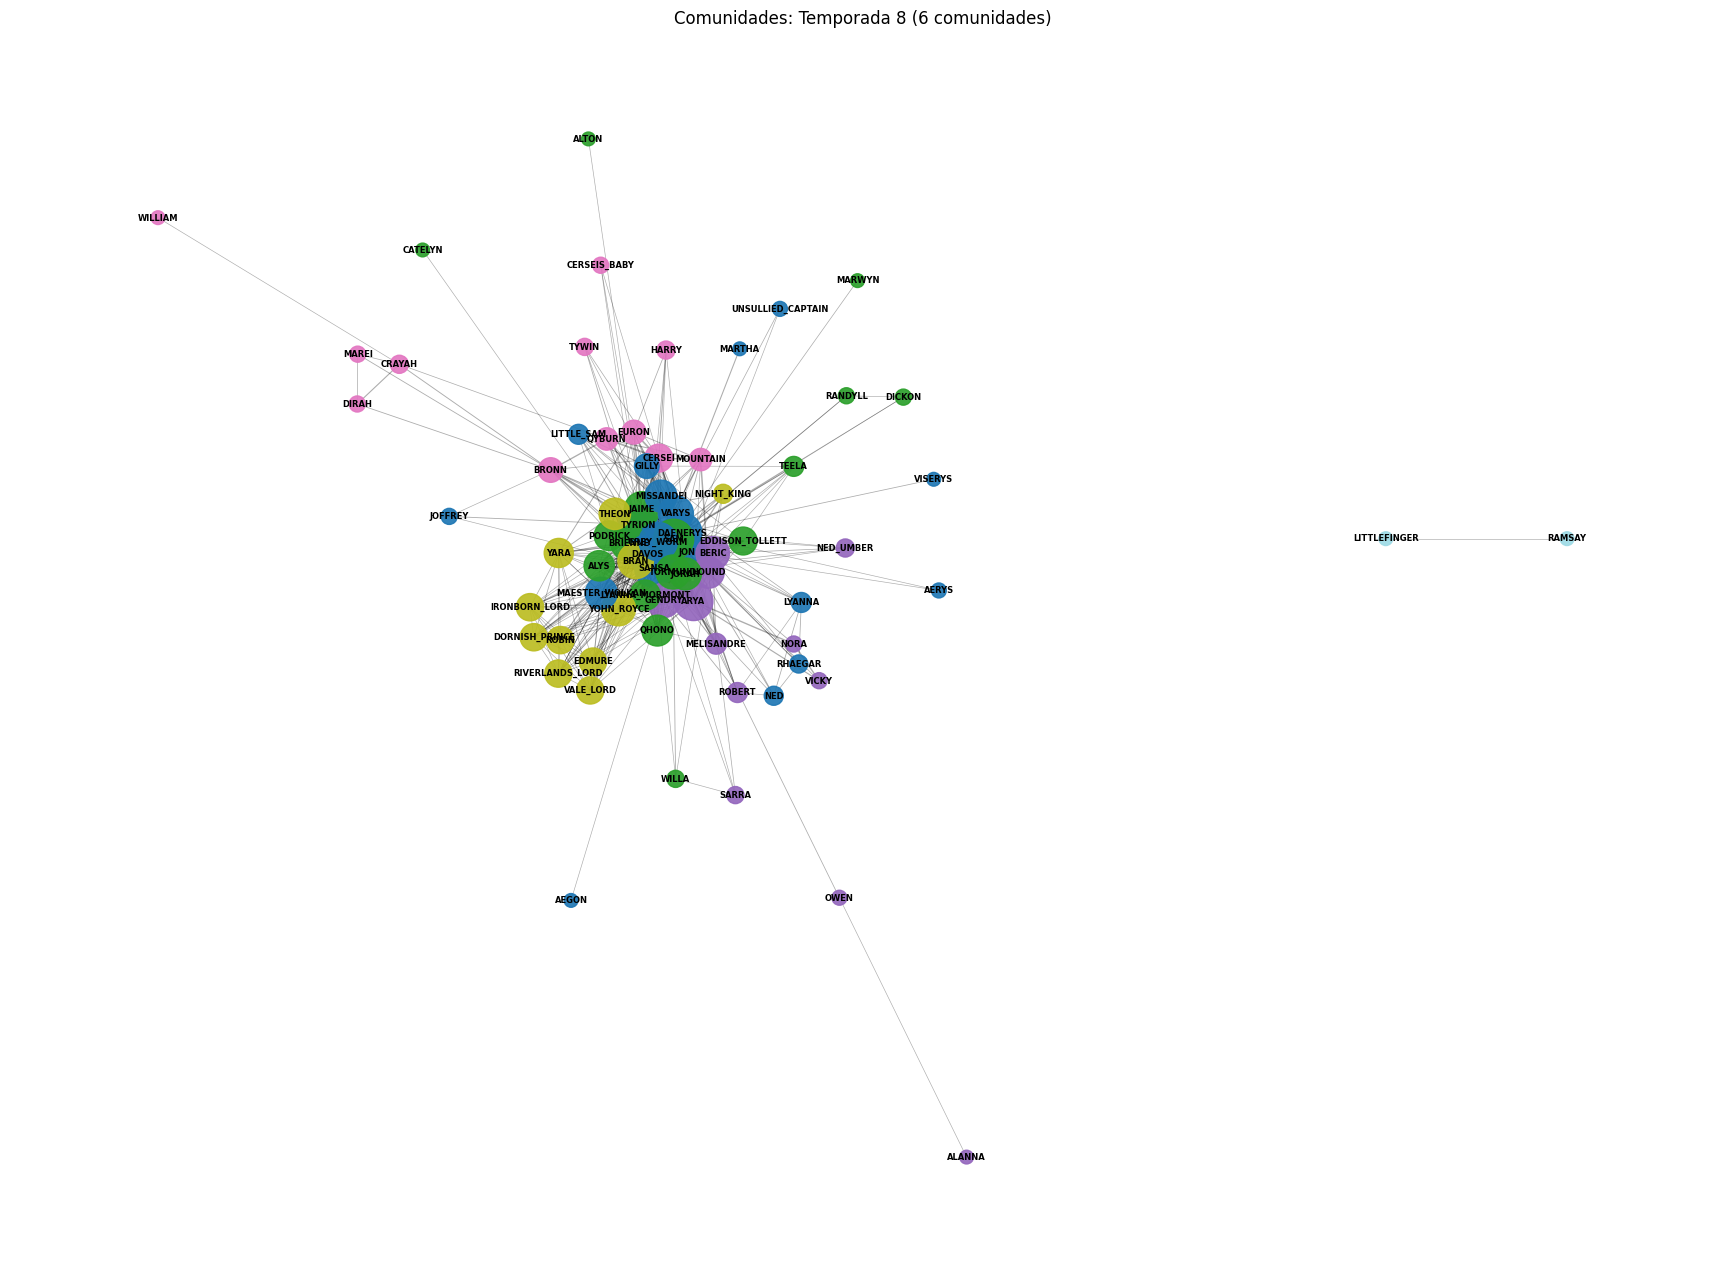

In [6]:
def layout_por_componentes(G, seed=42):
    componentes = sorted(nx.connected_components(G), key=len, reverse=True)
    pos = {}

    for idx, nos in enumerate(componentes):
        sub = G.subgraph(nos)

        if len(nos) == 1:
            sub_pos = {next(iter(nos)): np.array([0.0, 0.0])}
        elif len(nos) <= 3:
            sub_pos = nx.circular_layout(sub, scale=0.5)
        else:
            sub_pos = nx.spring_layout(
                sub, seed=seed + idx, weight="Weight", iterations=300, k=0.35, scale=3.0
            )

        valores = np.array(list(sub_pos.values()))
        centro = valores.mean(axis=0)
        deslocamento_x = 0 if idx == 0 else 4.5 + (idx - 1) * 1.5

        for no, p in sub_pos.items():
            pos[no] = (p[0] - centro[0] + deslocamento_x, p[1] - centro[1])

    return pos


def plot_comunidades(G, mapa, titulo, seed=42):
    plt.figure(figsize=(22, 16))
    pos = layout_por_componentes(G, seed=seed)

    graus = dict(G.degree())
    cores = [mapa[n] for n in G.nodes()]
    tamanhos = [80 + graus[n] * 18 for n in G.nodes()]

    pesos = [G[u][v].get("Weight", 1) for u, v in G.edges()]
    maior_peso = max(pesos) if pesos else 1
    larguras = [0.25 + 2.2 * (p / maior_peso) ** 0.5 for p in pesos]

    nx.draw_networkx_edges(G, pos, width=larguras, alpha=0.32)
    nx.draw_networkx_nodes(G, pos, node_color=cores, cmap=plt.cm.tab20, node_size=tamanhos, alpha=0.92)
    nx.draw_networkx_labels(G, pos, font_size=6, font_weight="bold")

    plt.title(titulo)
    plt.axis("off")
    plt.show()

plot_comunidades(G1, mapa_t1, f"Comunidades: Temporada 1 ({len(comunidades_t1)} comunidades)")
plot_comunidades(G8, mapa_t8, f"Comunidades: Temporada 8 ({len(comunidades_t8)} comunidades)")


## Síntese interpretativa

A rede da **Temporada 1** possui **126 vértices** e **549 arestas**. A rede da **Temporada 8** possui **74 vértices** e **553 arestas**. Assim, a Temporada 8 tem bem menos personagens, mas praticamente o mesmo número de conexões.

Isso aparece nas métricas: o grau médio sobe de **8.71** para **14.95**, a densidade sobe de **0.0697** para **0.2047**, e a transitividade sobe de **0.3833** para **0.6442**.

Logo, a Temporada 1 tem uma rede mais espalhada, com muitos personagens periféricos e alguns hubs. A Temporada 8 é menor, mais compacta, mais densa e mais agrupada, refletindo a concentração narrativa nos núcleos finais da série.
